# ILLM Lab 3 — Hindi IndicCorpV2: BPE & WordPiece
## Streaming-first, Colab-safe version

This notebook is designed to avoid materializing the enormous IndicCorpV2 Hindi corpus into Arrow/bin files.

### Assignment workflow
1. Load Hindi from IndicCorpV2.
2. **Stream the raw Hindi text files** instead of loading the complete dataset.
3. Sentence-tokenize the paragraph-level text.
4. Build exactly:
   - 1,000,000 training sentences
   - 1,000 development sentences
   - 1,000 test sentences
5. Use length-stratified sampling for dev/test.
6. Train and compare:
   - BPE
   - WordPiece
7. Training sizes:
   - 100K, 300K, 500K, 1M
8. Vocabulary sizes:
   - 20K, 30K, 50K
9. Evaluate dev/test tokenization quantitatively and qualitatively.
10. Save the resulting split files and experiment results.

### Critical correction
`hin_Deva` is the **dataset split name**, while the actual Hindi source files are `data/hi-*.txt`. The official repository configuration confirms this mapping. citeturn0search3turn0search4

The standard `load_dataset(..., split="hin_Deva")` route can invoke the dataset builder and cause huge file materialization in some environments. This notebook instead uses the repository's raw `data/hi-*.txt` files through Hugging Face Hub file streaming. Hugging Face documents that `streaming=True` prevents downloading the complete data files and streams supported text files progressively. citeturn0search0turn0search1

**Do not use `data_dir="data/hi_Deva"` or `data_dir="data/hin_Deva"`.**


# 0. Install only what is needed

We deliberately **do not upgrade NumPy**. This avoids the `_slice` / `numpy._core.umath` import problem seen earlier.

If Colab asks for a runtime restart after installation, restart once and continue.


In [ ]:
%pip -q install huggingface_hub tokenizers tqdm


In [ ]:
import os
import re
import math
import json
import random
import time
import fnmatch
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from huggingface_hub import HfApi, hf_hub_url
from tokenizers import Tokenizer
from tokenizers.models import BPE, WordPiece
from tokenizers.trainers import BpeTrainer, WordPieceTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import NFC

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Imports successful.")


NumPy: 2.1.3
Imports successful.


# 1. Configuration


In [ ]:
LANGUAGE_SPLIT = "hin_Deva"
REPO_ID = "ai4bharat/IndicCorpV2"
REPO_TYPE = "dataset"

DEV_SIZE = 1_000
TEST_SIZE = 1_000
MAX_TRAIN_SIZE = 1_000_000
TARGET_SENTENCES = MAX_TRAIN_SIZE + DEV_SIZE + TEST_SIZE

TRAINING_SIZES = [100_000, 300_000, 500_000, 1_000_000]
VOCAB_SIZES = [20_000, 30_000, 50_000]

FIXED_VOCAB_SIZE = 30_000
FIXED_TRAIN_SIZE = 1_000_000
N_LENGTH_STRATA = 10

WORKDIR = "/content/illm_lab3_hindi_streaming"
RESULTS_DIR = os.path.join(WORKDIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Repository:", REPO_ID)
print("Hindi split:", LANGUAGE_SPLIT)
print("Target sentences:", f"{TARGET_SENTENCES:,}")


Repository: ai4bharat/IndicCorpV2
Hindi split: hin_Deva
Target sentences: 1,002,000


# 2. Find the actual Hindi files on the Hub

The official configuration says:

`hin_Deva -> data/hi-*.txt`

Instead of asking the dataset builder to materialize the whole split, we list the repository files and select only the Hindi text shards matching `data/hi-*.txt`.

This is the important part that avoids the huge `.bin`/Arrow download.


In [ ]:
api = HfApi()

repo_files = list(
    api.list_repo_files(
        repo_id=REPO_ID,
        repo_type=REPO_TYPE
    )
)

hindi_files = sorted([
    f for f in repo_files
    if fnmatch.fnmatch(f, "data/hi-*.txt")
])

print("Number of Hindi source files:", len(hindi_files))

if not hindi_files:
    # Fail loudly rather than silently using the wrong language.
    raise RuntimeError(
        "No files matching data/hi-*.txt were found in IndicCorpV2. "
        "The repository layout may have changed; do not guess a different language path."
    )

print("First Hindi files:")
for f in hindi_files[:10]:
    print(" -", f)

if len(hindi_files) > 10:
    print("...")


Number of Hindi source files: 3
First Hindi files:
 - data/hi-1.txt
 - data/hi-2.txt
 - data/hi-3.txt


# 3. Stream each Hindi `.txt` shard directly

Hugging Face Hub provides URLs for individual repository files. We open each file using an HTTP stream, so the complete Hindi corpus is **never downloaded to Colab**.

We stop as soon as we have enough sentences for the assignment.

This is different from:

```python
load_dataset(..., streaming=True)
```

which can still depend on the dataset-builder/configuration path. Here we explicitly select the underlying `data/hi-*.txt` files that the official configuration maps to `hin_Deva`. citeturn0search3turn0search4


In [ ]:
import requests

def stream_text_file_from_hub(repo_id, filename, repo_type="dataset", timeout=60):
    url = hf_hub_url(
        repo_id=repo_id,
        filename=filename,
        repo_type=repo_type
    )

    # stream=True means requests does not load the complete file into memory.
    response = requests.get(url, stream=True, timeout=timeout)
    response.raise_for_status()

    # Iterate line-by-line. IndicCorpV2 files are text files.
    for raw_line in response.iter_lines(decode_unicode=True):
        if raw_line is None:
            continue
        yield raw_line

    response.close()


# 4. Sentence tokenizer

IndicCorpV2 rows are paragraph-level text, so the assignment requires sentence tokenization before creating the sentence-level split.

The tokenizer handles common sentence-final punctuation including:
- `.`
- `?`
- `!`
- Hindi danda `।`
- double danda `॥`
- common Unicode equivalents


In [ ]:
SENTENCE_BOUNDARY = re.compile(
    r'(?<=[\.\?\!।॥！？])(?:["“”\'’»)\]]+)?\s+|(?<=[\.\?\!।॥！？])$'
)

def normalize_paragraph(text):
    text = str(text)
    text = text.replace("\ufeff", "")
    text = text.replace("\u00a0", " ")
    text = re.sub(r"\s+", " ", text).strip()
    return text

def sentence_tokenize(paragraph):
    paragraph = normalize_paragraph(paragraph)
    if not paragraph:
        return []

    pieces = SENTENCE_BOUNDARY.split(paragraph)
    return [p.strip() for p in pieces if p and p.strip()]

# Test the function without downloading the corpus.
examples = [
    "यह पहला वाक्य है। यह दूसरा वाक्य है।",
    "आप कैसे हैं? मैं ठीक हूँ!",
    "यह एक उदाहरण है॥ दूसरा उदाहरण।"
]

for x in examples:
    print(x)
    print(sentence_tokenize(x))
    print()


यह पहला वाक्य है। यह दूसरा वाक्य है।
['यह पहला वाक्य है।', 'यह दूसरा वाक्य है।']

आप कैसे हैं? मैं ठीक हूँ!
['आप कैसे हैं?', 'मैं ठीक हूँ!']

यह एक उदाहरण है॥ दूसरा उदाहरण।
['यह एक उदाहरण है॥', 'दूसरा उदाहरण।']



# 5. Extract exactly enough unique Hindi sentences

Required:

`1,000,000 + 1,000 + 1,000 = 1,002,000`

We read Hindi shards progressively and stop immediately once enough unique sentences have been obtained.

**This is the only large data-reading step.** It can still take time because the notebook must physically read enough Hindi text and sentence-tokenize it, but it does not create a giant Arrow/bin copy of IndicCorpV2.


In [ ]:
sentences = []
seen = set()

start = time.time()

for file_no, filename in enumerate(hindi_files, start=1):
    print(f"Reading Hindi shard {file_no}/{len(hindi_files)}: {filename}")

    for paragraph in stream_text_file_from_hub(REPO_ID, filename, REPO_TYPE):
        for sentence in sentence_tokenize(paragraph):
            if sentence not in seen:
                seen.add(sentence)
                sentences.append(sentence)

            if len(sentences) >= TARGET_SENTENCES:
                break

        if len(sentences) >= TARGET_SENTENCES:
            break

    if len(sentences) >= TARGET_SENTENCES:
        break

elapsed = (time.time() - start) / 60

print(f"\nCollected: {len(sentences):,} unique sentences")
print(f"Time: {elapsed:.2f} minutes")

if len(sentences) < TARGET_SENTENCES:
    raise RuntimeError(
        f"Only {len(sentences):,} sentences were collected, "
        f"but {TARGET_SENTENCES:,} are required."
    )

sentences = sentences[:TARGET_SENTENCES]


Reading Hindi shard 1/3: data/hi-1.txt

Collected: 1,002,000 unique sentences
Time: 0.64 minutes


In [ ]:
# Corpus sanity checks.

sentence_lengths = np.array([len(s) for s in sentences], dtype=np.int32)

print("Total sentences:", f"{len(sentences):,}")
print("Minimum length:", int(sentence_lengths.min()))
print("Maximum length:", int(sentence_lengths.max()))
print("Mean length:", round(float(sentence_lengths.mean()), 2))
print("Median length:", round(float(np.median(sentence_lengths)), 2))

print("\nFirst 5 sentences:")
for s in sentences[:5]:
    print("-", s)


Total sentences: 1,002,000
Minimum length: 1
Maximum length: 6051
Mean length: 253.84
Median length: 174.0

First 5 sentences:
- à¤²à¥à¤à¥à¤ à¤à¥ à¤¬à¤¿à¤²à¥à¤ à¤¸à¤à¤¬à¤à¤§à¥ à¤¸à¥à¤µà¤¿à¤§à¤¾ à¤¦à¥à¤¨à¤¾ à¤¹à¥ à¤à¤¨à¤à¤¾ à¤à¤¾à¤®
- à¤à¤¨à¥à¤²à¥ 1987 à¤®à¥à¤ à¤à¤¸ à¤µà¤à¥à¤¤ à¤à¤¸à¥ à¤¹à¥ à¤¦à¥à¤°à¤¾à¤¹à¥ à¤ªà¤° à¤à¤¡à¤¼à¥ à¤¥à¥, à¤à¤¬ à¤ªà¥à¤°à¥à¤µ à¤à¤ªà¤ªà¥à¤°à¤§à¤¾à¤¨à¤®à¤à¤¤à¥à¤°à¥ à¤¦à¥à¤µà¥à¤²à¤¾à¤² à¤¨à¥ à¤
- à¤ªà¤¨à¥ à¤ªà¥à¤¤à¥à¤° à¤à¤®à¤ªà¥à¤°à¤à¤¾à¤¶ à¤à¥à¤à¤¾à¤²à¤¾ à¤à¥ à¤
- à¤ªà¤¨à¤¾ à¤°à¤¾à¤à¤¨à¥à¤¤à¤¿à¤ à¤à¤¤à¥à¤¤à¤°à¤¾à¤§à¤¿à¤à¤¾à¤°à¥ à¤à¥à¤·à¤¿à¤¤ à¤à¤¿à¤¯à¤¾ à¤¥à¤¾à¥¤ à¤¹à¤¾à¤²à¤¾à¤à¤à¤¿ à¤¤à¤¬ à¤ªà¤¾à¤°à¥à¤à¥ à¤ªà¤° à¤¦à¥à¤µà¥à¤²à¤¾à¤² à¤à¥ à¤®à¤à¤¬à¥à¤¤ à¤ªà¤à¤¡à¤¼ à¤à¥ à¤à¤²à¤¤à¥ à¤ªà¤¾à¤°à¥à¤à¥ à¤à¥à¤à¤¨à¥ à¤¸à¥ à¤¬à¤ à¤à¤ à¤¥à¥à¥¤ 1989 à¤®à¥à¤ à¤¦à¥à¤µà¥à¤²à¤¾à¤² à¤à¥à¤¨à¥à¤¦à¥à¤° à¤à¥ à¤°à¤¾à¤à¤¨à¥à¤¤à¤¿ à¤®à¥à¤ à¤¸à¤à¥à¤°à¤¿à¤¯ à¤¹à¥ à¤à¤ à¤¥à¥ à¤à

# 6. Length-stratified train/dev/test split

The assignment requires 1000 development and 1000 test sentences while maintaining a sentence-length distribution.

We:
1. rank sentences by character length;
2. divide them into 10 equal-frequency length strata;
3. allocate dev/test samples proportionally across the strata;
4. use all remaining sentences as the 1M training pool.

A fixed seed makes the split reproducible.


In [ ]:
def proportional_allocation(counts, total):
    counts = np.asarray(counts, dtype=float)
    raw = counts / counts.sum() * total
    base = np.floor(raw).astype(int)

    remaining = int(total - base.sum())
    if remaining > 0:
        fractional_order = np.argsort(-(raw - base))
        base[fractional_order[:remaining]] += 1

    return base

rng = np.random.default_rng(SEED)

dev_alloc = proportional_allocation(stratum_counts.values, DEV_SIZE)
test_alloc = proportional_allocation(stratum_counts.values, TEST_SIZE)

dev_indices = []
test_indices = []

for sid in range(N_LENGTH_STRATA):
    available = np.flatnonzero(stratum_id == sid)

    chosen = rng.choice(
        available,
        size=int(dev_alloc[sid] + test_alloc[sid]),
        replace=False
    )
    rng.shuffle(chosen)

    d = int(dev_alloc[sid])
    t = int(test_alloc[sid])

    dev_indices.extend(chosen[:d])
    test_indices.extend(chosen[d:d+t])

dev_indices = np.array(dev_indices, dtype=np.int64)
test_indices = np.array(test_indices, dtype=np.int64)

held_out = set(dev_indices.tolist()) | set(test_indices.tolist())

train_indices = np.array(
    [i for i in range(len(sentences)) if i not in held_out],
    dtype=np.int64
)

dev_sentences = [sentences[i] for i in dev_indices]
test_sentences = [sentences[i] for i in test_indices]
train_pool = [sentences[i] for i in train_indices]

assert len(train_pool) == MAX_TRAIN_SIZE
assert len(dev_sentences) == DEV_SIZE
assert len(test_sentences) == TEST_SIZE
assert set(dev_indices).isdisjoint(set(test_indices))

print("Train:", f"{len(train_pool):,}")
print("Dev:", f"{len(dev_sentences):,}")
print("Test:", f"{len(test_sentences):,}")


Train: 1,000,000
Dev: 1,000
Test: 1,000


In [ ]:
# Build 10 approximately equal-frequency length strata.

order = np.argsort(sentence_lengths, kind="stable")
stratum_id = np.empty(len(sentences), dtype=np.int16)

for rank, idx in enumerate(order):
    stratum_id[idx] = min(
        N_LENGTH_STRATA - 1,
        (rank * N_LENGTH_STRATA) // len(sentences)
    )

stratum_counts = pd.Series(stratum_id).value_counts().sort_index()
display(stratum_counts.to_frame("all_sentences"))


,all_sentences
0,100200
1,100200
2,100200
3,100200
4,100200
5,100200
6,100200
7,100200
8,100200
9,100200


,all,dev,test
0,100200,100,100
1,100200,100,100
2,100200,100,100
3,100200,100,100
4,100200,100,100
5,100200,100,100
6,100200,100,100
7,100200,100,100
8,100200,100,100
9,100200,100,100



DEV:


,0
count,1000.000000
mean,254.874000
std,252.273181
min,6.000000
25%,95.000000
50%,174.500000
75%,323.000000
max,2151.000000



TEST:


,0
count,1000.000000
mean,253.933000
std,248.992284
min,12.000000
25%,94.750000
50%,174.500000
75%,320.000000
max,2023.000000


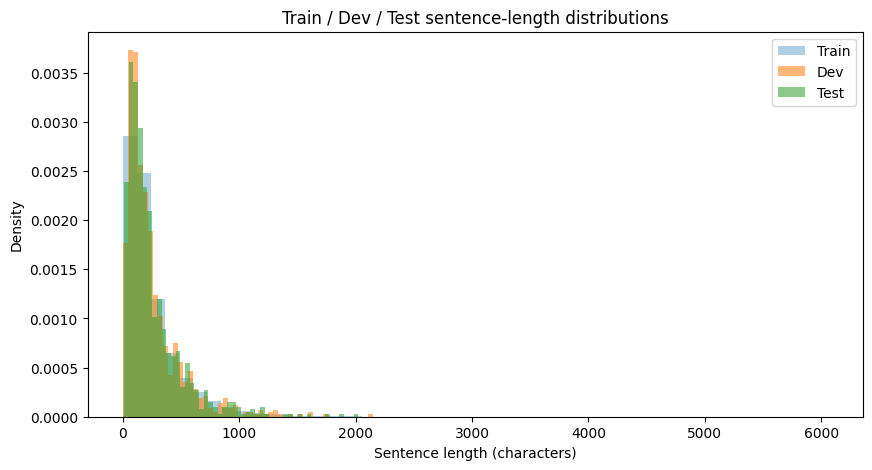

In [ ]:
# Verify the length distribution.

distribution = pd.DataFrame({
    "all": pd.Series(stratum_id).value_counts().sort_index(),
    "dev": pd.Series(stratum_id[dev_indices]).value_counts().sort_index(),
    "test": pd.Series(stratum_id[test_indices]).value_counts().sort_index()
}).fillna(0).astype(int)

display(distribution)

print("\nDEV:")
display(pd.Series([len(x) for x in dev_sentences]).describe())

print("\nTEST:")
display(pd.Series([len(x) for x in test_sentences]).describe())

plt.figure(figsize=(10, 5))
plt.hist([len(x) for x in train_pool], bins=50, density=True, alpha=0.35, label="Train")
plt.hist([len(x) for x in dev_sentences], bins=50, density=True, alpha=0.55, label="Dev")
plt.hist([len(x) for x in test_sentences], bins=50, density=True, alpha=0.55, label="Test")
plt.xlabel("Sentence length (characters)")
plt.ylabel("Density")
plt.title("Train / Dev / Test sentence-length distributions")
plt.legend()
plt.show()


In [ ]:
# Save exact split files for reuse in Lab 4.

split_paths = {}

for name, data in [
    ("train_1M.txt", train_pool),
    ("dev_1000.txt", dev_sentences),
    ("test_1000.txt", test_sentences),
]:
    path = os.path.join(WORKDIR, name)
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(data))
    split_paths[name] = path
    print("Saved:", path)


Saved: /content/illm_lab3_hindi_streaming/train_1M.txt
Saved: /content/illm_lab3_hindi_streaming/dev_1000.txt
Saved: /content/illm_lab3_hindi_streaming/test_1000.txt


In [ ]:
# ============================================================
# BPE TOKENIZATION FROM SCRATCH
# ============================================================

from collections import Counter
import re


# ------------------------------------------------------------
# STEP 1: Prepare vocabulary
# ------------------------------------------------------------

def get_word_freqs(corpus):
    """
    Convert corpus into word frequencies.

    Example:
    "low lower lowest"

    -> {
        ('l','o','w','</w>'): 1,
        ...
    }
    """

    words = corpus.lower().split()
    word_freqs = Counter(words)

    vocab = {}

    for word, freq in word_freqs.items():
        # Represent each word as characters + </w>
        chars = tuple(list(word) + ["</w>"])
        vocab[chars] = freq

    return vocab


# ------------------------------------------------------------
# STEP 2: Count adjacent symbol pairs
# ------------------------------------------------------------

def get_pair_counts(vocab):
    """
    Count frequency of every adjacent pair.
    """

    pairs = Counter()

    for symbols, freq in vocab.items():
        for i in range(len(symbols) - 1):
            pair = (symbols[i], symbols[i + 1])
            pairs[pair] += freq

    return pairs


# ------------------------------------------------------------
# STEP 3: Merge the most frequent pair
# ------------------------------------------------------------

def merge_pair(pair, vocab):
    """
    Merge the selected pair throughout the vocabulary.
    """

    new_vocab = {}

    bigram = pair

    for symbols, freq in vocab.items():

        new_symbols = []
        i = 0

        while i < len(symbols):

            # Check whether current and next symbol
            # form the selected pair
            if (
                i < len(symbols) - 1
                and symbols[i] == bigram[0]
                and symbols[i + 1] == bigram[1]
            ):
                new_symbols.append(symbols[i] + symbols[i + 1])
                i += 2
            else:
                new_symbols.append(symbols[i])
                i += 1

        new_vocab[tuple(new_symbols)] = freq

    return new_vocab


# ------------------------------------------------------------
# STEP 4: Train BPE
# ------------------------------------------------------------

def train_bpe(corpus, num_merges=10):

    vocab = get_word_freqs(corpus)

    merges = []

    print("Initial vocabulary:")
    for word, freq in vocab.items():
        print(word, ":", freq)

    print("\n" + "=" * 60)

    for iteration in range(num_merges):

        pair_counts = get_pair_counts(vocab)

        if not pair_counts:
            break

        # Select most frequent pair
        best_pair, best_freq = pair_counts.most_common(1)[0]

        print(
            f"Merge {iteration + 1}: "
            f"{best_pair}  -> frequency = {best_freq}"
        )

        merges.append(best_pair)

        vocab = merge_pair(best_pair, vocab)

    return vocab, merges


# ------------------------------------------------------------
# STEP 5: Tokenize a new word using learned merges
# ------------------------------------------------------------

def tokenize_bpe(word, merges):

    symbols = tuple(list(word.lower()) + ["</w>"])

    for pair in merges:

        new_symbols = []
        i = 0

        while i < len(symbols):

            if (
                i < len(symbols) - 1
                and symbols[i] == pair[0]
                and symbols[i + 1] == pair[1]
            ):
                new_symbols.append(symbols[i] + symbols[i + 1])
                i += 2
            else:
                new_symbols.append(symbols[i])
                i += 1

        symbols = tuple(new_symbols)

    return list(symbols)


# ============================================================
# DEMO
# ============================================================

corpus = """
low low low lower lower lowest
newer newer newer newest
"""

bpe_vocab, bpe_merges = train_bpe(
    corpus,
    num_merges=10
)

print("\n" + "=" * 60)
print("LEARNED MERGES:")
print(bpe_merges)

print("\nFINAL BPE VOCABULARY:")
for word, freq in bpe_vocab.items():
    print(word, ":", freq)

print("\nTOKENIZATION:")
test_words = ["low", "lower", "lowest", "newest"]

for word in test_words:
    print(word, "->", tokenize_bpe(word, bpe_merges))

In [ ]:
# ============================================================
# WORDPIECE TOKENIZATION FROM SCRATCH
# ============================================================

from collections import Counter


# ------------------------------------------------------------
# STEP 1: Build initial vocabulary
# ------------------------------------------------------------

def get_wordpiece_vocab(corpus):

    words = corpus.lower().split()

    word_freqs = Counter(words)

    vocab = {}

    for word, freq in word_freqs.items():

        symbols = []

        for i, char in enumerate(word):

            if i == 0:
                symbols.append(char)
            else:
                symbols.append("##" + char)

        vocab[tuple(symbols)] = freq

    return vocab


# ------------------------------------------------------------
# STEP 2: Calculate symbol frequencies
# ------------------------------------------------------------

def get_symbol_counts(vocab):

    counts = Counter()

    for symbols, freq in vocab.items():

        for symbol in symbols:
            counts[symbol] += freq

    return counts


# ------------------------------------------------------------
# STEP 3: Calculate pair frequencies
# ------------------------------------------------------------

def get_pair_counts_wordpiece(vocab):

    pair_counts = Counter()

    for symbols, freq in vocab.items():

        for i in range(len(symbols) - 1):

            pair = (
                symbols[i],
                symbols[i + 1]
            )

            pair_counts[pair] += freq

    return pair_counts


# ------------------------------------------------------------
# STEP 4: WordPiece score
# ------------------------------------------------------------

def get_best_wordpiece_pair(vocab):

    symbol_counts = get_symbol_counts(vocab)

    pair_counts = get_pair_counts_wordpiece(vocab)

    best_pair = None
    best_score = -1

    for pair, pair_freq in pair_counts.items():

        first, second = pair

        score = (
            pair_freq /
            (
                symbol_counts[first] *
                symbol_counts[second]
            )
        )

        if score > best_score:

            best_score = score
            best_pair = pair

    return best_pair, best_score


# ------------------------------------------------------------
# STEP 5: Merge WordPiece pair
# ------------------------------------------------------------

def merge_wordpiece_pair(pair, vocab):

    new_vocab = {}

    first, second = pair

    for symbols, freq in vocab.items():

        new_symbols = []

        i = 0

        while i < len(symbols):

            if (
                i < len(symbols) - 1
                and symbols[i] == first
                and symbols[i + 1] == second
            ):

                # Remove ## from second token
                merged = first + second.replace("##", "")

                new_symbols.append(merged)

                i += 2

            else:

                new_symbols.append(symbols[i])

                i += 1

        new_vocab[tuple(new_symbols)] = freq

    return new_vocab


# ------------------------------------------------------------
# STEP 6: Train WordPiece
# ------------------------------------------------------------

def train_wordpiece(corpus, num_merges=10):

    vocab = get_wordpiece_vocab(corpus)

    merges = []

    print("INITIAL VOCABULARY")

    for word, freq in vocab.items():
        print(word, ":", freq)

    print("\n" + "=" * 60)

    for iteration in range(num_merges):

        best_pair, best_score = get_best_wordpiece_pair(vocab)

        if best_pair is None:
            break

        print(
            f"Merge {iteration + 1}: "
            f"{best_pair}"
        )

        print(
            f"Score = {best_score:.8f}"
        )

        merges.append(best_pair)

        vocab = merge_wordpiece_pair(
            best_pair,
            vocab
        )

    return vocab, merges


# ------------------------------------------------------------
# STEP 7: Tokenize a word
# ------------------------------------------------------------

def tokenize_wordpiece(word, vocab):

    word = word.lower()

    tokens = []

    start = 0

    while start < len(word):

        end = len(word)

        current_token = None

        while start < end:

            substring = word[start:end]

            if start > 0:
                substring = "##" + substring

            if substring in vocab:

                current_token = substring
                break

            end -= 1

        if current_token is None:

            return ["[UNK]"]

        tokens.append(current_token)

        # Remove ## prefix only for indexing
        if current_token.startswith("##"):
            piece_length = len(current_token) - 2
        else:
            piece_length = len(current_token)

        start += piece_length

    return tokens


# ============================================================
# DEMO
# ============================================================

corpus = """
low low low lower lower lowest
newer newer newer newest
"""

wp_vocab, wp_merges = train_wordpiece(
    corpus,
    num_merges=10
)

print("\n" + "=" * 60)

print("LEARNED WORDPIECE MERGES:")
print(wp_merges)

print("\nFINAL WORDPIECE VOCABULARY:")

for word, freq in wp_vocab.items():
    print(word, ":", freq)

# Create token set
final_vocab = set()

for symbols in wp_vocab.keys():

    for symbol in symbols:
        final_vocab.add(symbol)

print("\nTOKENIZATION:")

for word in ["low", "lower", "lowest", "newest"]:

    print(
        word,
        "->",
        tokenize_wordpiece(word, final_vocab)
    )

# 7. BPE and WordPiece tokenizers

The two algorithms are trained on exactly the same training subsets.

For fair comparisons:
- same training sentences;
- same vocabulary size;
- same Unicode normalization;
- same whitespace pre-tokenization;
- same dev/test data.

The algorithm itself is the changing factor.


In [ ]:
def make_bpe_tokenizer(vocab_size):
    tokenizer = Tokenizer(BPE(unk_token="<unk>"))
    tokenizer.normalizer = NFC()
    tokenizer.pre_tokenizer = Whitespace()

    trainer = BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["<unk>"]
    )
    return tokenizer, trainer


def make_wordpiece_tokenizer(vocab_size):
    tokenizer = Tokenizer(WordPiece(unk_token="[UNK]"))
    tokenizer.normalizer = NFC()
    tokenizer.pre_tokenizer = Whitespace()

    trainer = WordPieceTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["[UNK]"],
        continuing_subword_prefix="##"
    )
    return tokenizer, trainer


def train_tokenizer(algorithm, train_data, vocab_size, save_name):
    if algorithm == "BPE":
        tokenizer, trainer = make_bpe_tokenizer(vocab_size)
    elif algorithm == "WordPiece":
        tokenizer, trainer = make_wordpiece_tokenizer(vocab_size)
    else:
        raise ValueError("algorithm must be BPE or WordPiece")

    tokenizer.train_from_iterator(
        train_data,
        trainer=trainer,
        length=len(train_data)
    )

    save_path = os.path.join(WORKDIR, save_name)
    tokenizer.save(save_path)

    return tokenizer, save_path


# 8. Evaluation metrics

For every tokenizer we measure:
- actual vocabulary size;
- total tokens;
- average tokens per sentence;
- average tokens per whitespace-delimited word;
- tokens per character;
- UNK rate.

These are descriptive tokenization metrics. They are used to compare how segmentation changes with training-data and vocabulary size.


In [ ]:
def evaluate_tokenizer(tokenizer, texts, split_name):
    encodings = tokenizer.encode_batch(texts)

    token_counts = np.array(
        [len(enc.tokens) for enc in encodings],
        dtype=np.int32
    )

    total_tokens = int(token_counts.sum())
    total_chars = sum(len(t) for t in texts)
    total_words = sum(len(re.findall(r"\S+", t)) for t in texts)

    unk_token = "<unk>" if isinstance(tokenizer.model, BPE) else "[UNK]"
    unk_count = sum(enc.tokens.count(unk_token) for enc in encodings)

    return {
        "split": split_name,
        "sentences": len(texts),
        "total_tokens": total_tokens,
        "avg_tokens_per_sentence": float(token_counts.mean()),
        "avg_tokens_per_word": float(total_tokens / max(1, total_words)),
        "tokens_per_character": float(total_tokens / max(1, total_chars)),
        "unk_rate": float(unk_count / max(1, total_tokens)),
        "vocab_size_actual": int(tokenizer.get_vocab_size()),
    }


def show_examples(tokenizer, texts, n=5):
    rows = []
    for text in texts[:n]:
        enc = tokenizer.encode(text)
        rows.append({
            "sentence": text,
            "tokens": " | ".join(enc.tokens),
            "num_tokens": len(enc.tokens)
        })
    return pd.DataFrame(rows)


# 9. Experiment A — Training size

Fixed vocabulary: **30,000**

Training sizes:
- 100K
- 300K
- 500K
- 1M

Both BPE and WordPiece are trained at each size.


In [ ]:
# Shuffle the 1M training pool once for representative nested subsets.

rng_train = np.random.default_rng(SEED)
train_order = rng_train.permutation(len(train_pool))
train_shuffled = [train_pool[i] for i in train_order]

size_results = []
size_tokenizers = {}

for train_size in TRAINING_SIZES:
    subset = train_shuffled[:train_size]

    for algorithm in ["BPE", "WordPiece"]:
        name = f"{algorithm}_train{train_size}_vocab{FIXED_VOCAB_SIZE}"

        print("\n" + "=" * 90)
        print(name)

        tokenizer, path = train_tokenizer(
            algorithm,
            subset,
            FIXED_VOCAB_SIZE,
            name + ".json"
        )
        size_tokenizers[name] = tokenizer

        for split_name, texts in [
            ("dev", dev_sentences),
            ("test", test_sentences)
        ]:
            row = evaluate_tokenizer(tokenizer, texts, split_name)
            row.update({
                "algorithm": algorithm,
                "train_size": train_size,
                "vocab_size": FIXED_VOCAB_SIZE
            })
            size_results.append(row)

size_results_df = pd.DataFrame(size_results)
display(size_results_df.sort_values(["train_size", "algorithm", "split"]))



BPE_train100000_vocab30000

WordPiece_train100000_vocab30000

BPE_train300000_vocab30000

WordPiece_train300000_vocab30000

BPE_train500000_vocab30000

WordPiece_train500000_vocab30000

BPE_train1000000_vocab30000

WordPiece_train1000000_vocab30000


,split,sentences,total_tokens,avg_tokens_per_sentence,avg_tokens_per_word,tokens_per_character,unk_rate,vocab_size_actual,algorithm,train_size,vocab_size
0,dev,1000,156989,156.989,7.759057,0.615947,0.000000,6464,BPE,100000,30000
1,test,1000,156322,156.322,7.726855,0.615603,0.000006,6464,BPE,100000,30000
2,dev,1000,156998,156.998,7.759502,0.615983,0.000000,6982,WordPiece,100000,30000
3,test,1000,156326,156.326,7.727053,0.615619,0.000006,6982,WordPiece,100000,30000
4,dev,1000,156934,156.934,7.756339,0.615732,0.000000,12680,BPE,300000,30000
5,test,1000,156264,156.264,7.723988,0.615375,0.000000,12680,BPE,300000,30000
6,dev,1000,156935,156.935,7.756388,0.615736,0.000000,13731,WordPiece,300000,30000
7,test,1000,156262,156.262,7.723889,0.615367,0.000000,13731,WordPiece,300000,30000
8,dev,1000,156922,156.922,7.755746,0.615685,0.000000,17135,BPE,500000,30000
9,test,1000,156238,156.238,7.722703,0.615273,0.000000,17135,BPE,500000,30000


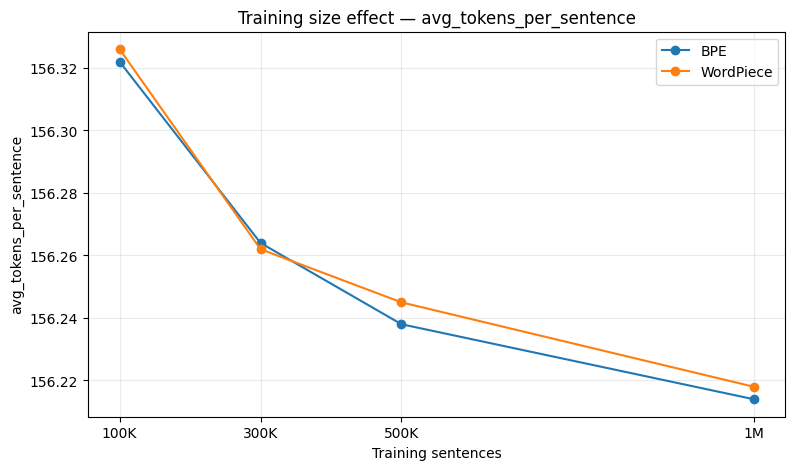

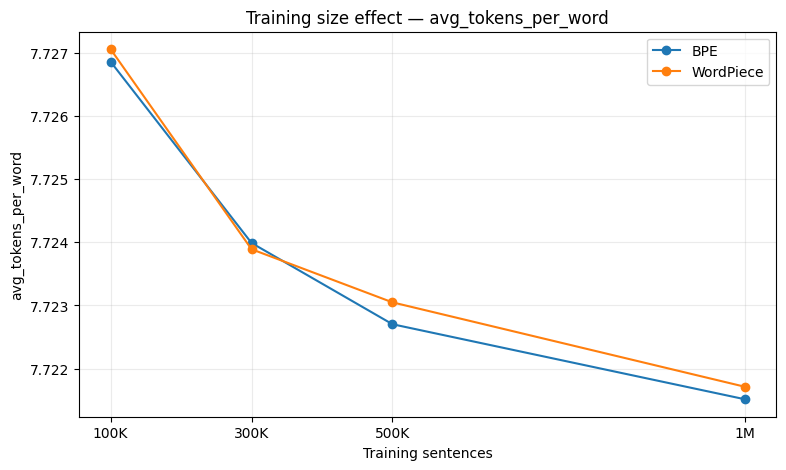

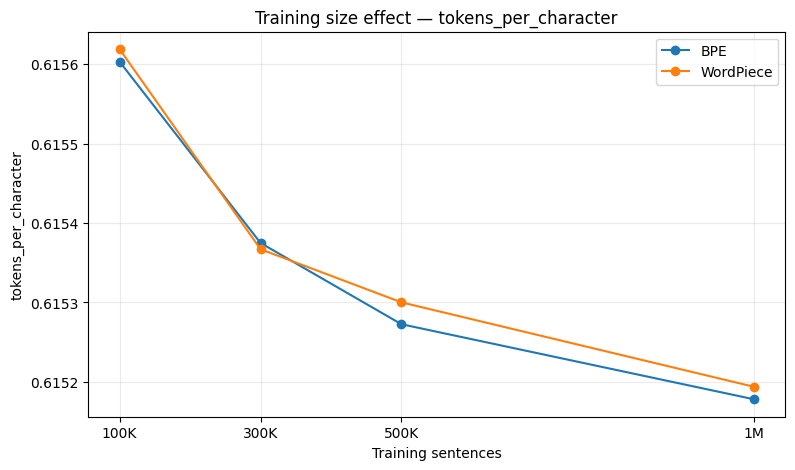

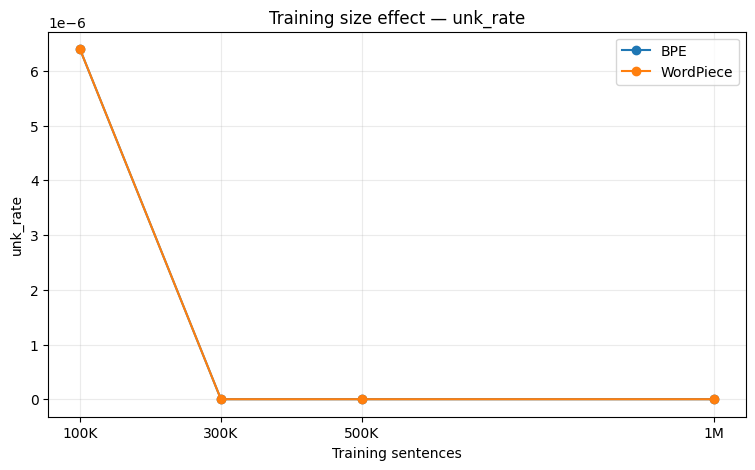

In [ ]:
size_test = size_results_df[size_results_df["split"] == "test"].copy()

for metric in [
    "avg_tokens_per_sentence",
    "avg_tokens_per_word",
    "tokens_per_character",
    "unk_rate"
]:
    plt.figure(figsize=(9, 5))
    for algorithm in ["BPE", "WordPiece"]:
        d = size_test[size_test["algorithm"] == algorithm]
        plt.plot(
            d["train_size"],
            d[metric],
            marker="o",
            label=algorithm
        )

    plt.xlabel("Training sentences")
    plt.ylabel(metric)
    plt.title(f"Training size effect — {metric}")
    plt.xticks(TRAINING_SIZES, ["100K", "300K", "500K", "1M"])
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.show()


In [ ]:
# Qualitative examples for training-size experiment.

sample_texts = test_sentences[:5]

for algorithm in ["BPE", "WordPiece"]:
    print("\n" + "#" * 100)
    print(algorithm)

    for train_size in TRAINING_SIZES:
        name = f"{algorithm}_train{train_size}_vocab{FIXED_VOCAB_SIZE}"
        print(f"\n--- {train_size:,} training sentences ---")
        display(show_examples(size_tokenizers[name], sample_texts))



####################################################################################################
BPE

--- 100,000 training sentences ---


,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20



--- 300,000 training sentences ---


,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20



--- 500,000 training sentences ---


...

,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20



--- 500,000 training sentences ---


,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20



--- 1,000,000 training sentences ---


,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20


# 10. Experiment B — Vocabulary size

Fixed training data: **1,000,000 sentences**

Vocabulary sizes:
- 20K
- 30K
- 50K

Both BPE and WordPiece are trained at each vocabulary size.


In [ ]:
vocab_results = []
vocab_tokenizers = {}

fixed_train = train_shuffled[:FIXED_TRAIN_SIZE]

for vocab_size in VOCAB_SIZES:
    for algorithm in ["BPE", "WordPiece"]:
        name = f"{algorithm}_train{FIXED_TRAIN_SIZE}_vocab{vocab_size}"

        print("\n" + "=" * 90)
        print(name)

        tokenizer, path = train_tokenizer(
            algorithm,
            fixed_train,
            vocab_size,
            name + ".json"
        )
        vocab_tokenizers[name] = tokenizer

        for split_name, texts in [
            ("dev", dev_sentences),
            ("test", test_sentences)
        ]:
            row = evaluate_tokenizer(tokenizer, texts, split_name)
            row.update({
                "algorithm": algorithm,
                "train_size": FIXED_TRAIN_SIZE,
                "vocab_size": vocab_size
            })
            vocab_results.append(row)

vocab_results_df = pd.DataFrame(vocab_results)
display(vocab_results_df.sort_values(["vocab_size", "algorithm", "split"]))



BPE_train1000000_vocab20000

WordPiece_train1000000_vocab20000

BPE_train1000000_vocab30000

WordPiece_train1000000_vocab30000

BPE_train1000000_vocab50000

WordPiece_train1000000_vocab50000


,split,sentences,total_tokens,avg_tokens_per_sentence,avg_tokens_per_word,tokens_per_character,unk_rate,vocab_size_actual,algorithm,train_size,vocab_size
0,dev,1000,156915,156.915,7.755400,0.615657,0.0,20000,BPE,1000000,20000
1,test,1000,156224,156.224,7.722011,0.615217,0.0,20000,BPE,1000000,20000
2,dev,1000,156919,156.919,7.755597,0.615673,0.0,20000,WordPiece,1000000,20000
3,test,1000,156232,156.232,7.722406,0.615249,0.0,20000,WordPiece,1000000,20000
4,dev,1000,156910,156.910,7.755152,0.615638,0.0,25640,BPE,1000000,30000
5,test,1000,156214,156.214,7.721516,0.615178,0.0,25640,BPE,1000000,30000
6,dev,1000,156913,156.913,7.755301,0.615649,0.0,27821,WordPiece,1000000,30000
7,test,1000,156218,156.218,7.721714,0.615194,0.0,27821,WordPiece,1000000,30000
8,dev,1000,156910,156.910,7.755152,0.615638,0.0,25640,BPE,1000000,50000
9,test,1000,156214,156.214,7.721516,0.615178,0.0,25640,BPE,1000000,50000


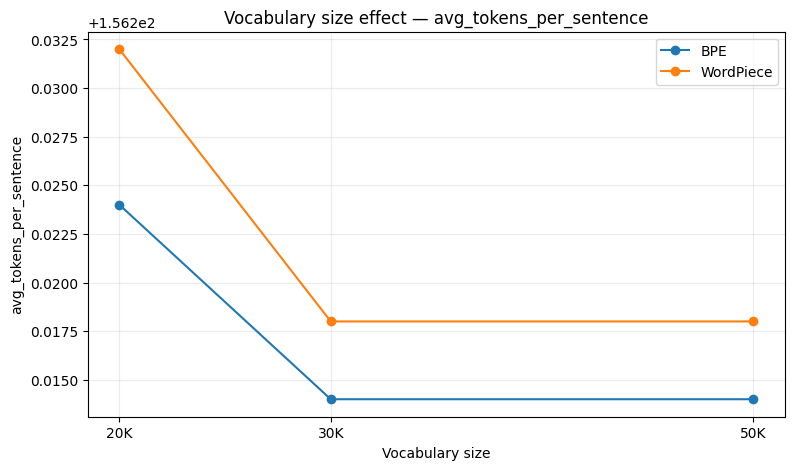

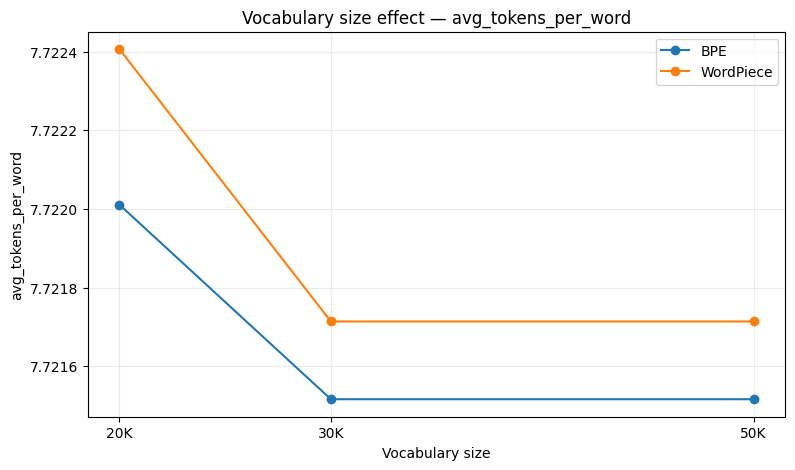

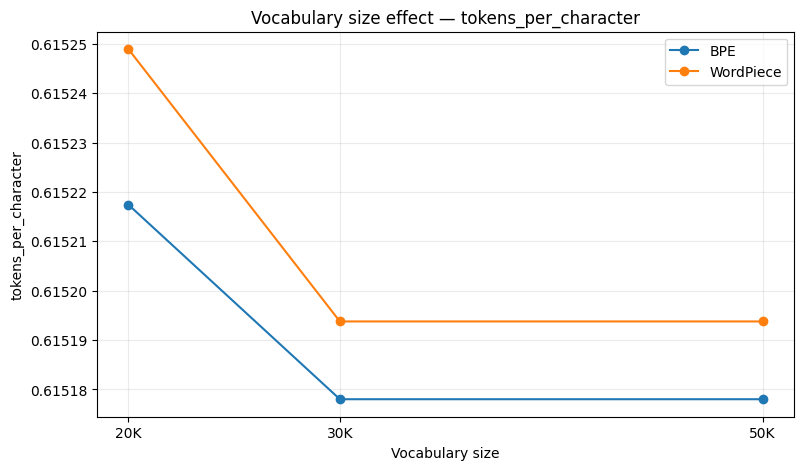

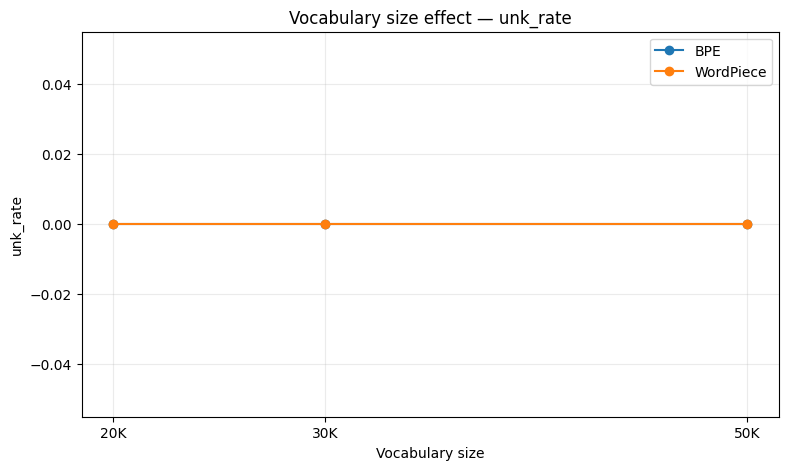

In [ ]:
vocab_test = vocab_results_df[vocab_results_df["split"] == "test"].copy()

for metric in [
    "avg_tokens_per_sentence",
    "avg_tokens_per_word",
    "tokens_per_character",
    "unk_rate"
]:
    plt.figure(figsize=(9, 5))

    for algorithm in ["BPE", "WordPiece"]:
        d = vocab_test[vocab_test["algorithm"] == algorithm]
        plt.plot(
            d["vocab_size"],
            d[metric],
            marker="o",
            label=algorithm
        )

    plt.xlabel("Vocabulary size")
    plt.ylabel(metric)
    plt.title(f"Vocabulary size effect — {metric}")
    plt.xticks(VOCAB_SIZES, ["20K", "30K", "50K"])
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.show()


In [ ]:
# Qualitative examples for vocabulary-size experiment.

for algorithm in ["BPE", "WordPiece"]:
    print("\n" + "#" * 100)
    print(algorithm)

    for vocab_size in VOCAB_SIZES:
        name = f"{algorithm}_train{FIXED_TRAIN_SIZE}_vocab{vocab_size}"
        print(f"\n--- Vocabulary = {vocab_size:,} ---")
        display(show_examples(vocab_tokenizers[name], sample_texts))



####################################################################################################
BPE

--- Vocabulary = 20,000 ---


,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20



--- Vocabulary = 30,000 ---


,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20



--- Vocabulary = 50,000 ---


...

,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20



--- Vocabulary = 30,000 ---


,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20



--- Vocabulary = 50,000 ---


,sentence,tokens,num_tokens
0,à¤ªà¤®à¤¾à¤¨ à¤¹à¥à¥¤'',à | ¤ | ªà | ¤® | à | ¤¾ | à | ¤¨ | à | ¤¹ | à...,14
1,à¤à¤¸ à¤®à¥à¤²à¤¾à¤à¤¾à¤¤ à¤à¤¾ à¤à¤¨à¤à...,à | ¤ | à | ¤¸ | à | ¤® | à | ¥ | à | ¤² | à...,32
2,à¤¯à¥ à¤¹à¥ 18 à¤¸à¤à¤¿à¤µ,à | ¤¯ | à | ¥ | à | ¤¹ | à | ¥ | 18 | à | ¤...,18
3,à¤¬ à¤¤à¤ 200 à¤¸à¥ à¤,à | ¤¬ | à | ¤¤ | à | ¤ | 200 | à | ¤¸ | à | ...,13
4,à¤à¥à¤à¥ à¤à¥à¤à¤¸ à¤¹à¥.,à | ¤ | à | ¥ | à | ¤ | à | ¥ | à | ¤ | à...,20


# 11. Direct comparison and findings

The following tables are generated from the actual experiment outputs. No result is hard-coded.


In [ ]:
print("=== Training-size experiment: TEST ===")
display(
    size_test[
        [
            "train_size",
            "algorithm",
            "vocab_size_actual",
            "avg_tokens_per_sentence",
            "avg_tokens_per_word",
            "tokens_per_character",
            "unk_rate"
        ]
    ].sort_values(["train_size", "algorithm"])
)

print("\n=== Vocabulary-size experiment: TEST ===")
display(
    vocab_test[
        [
            "vocab_size",
            "algorithm",
            "vocab_size_actual",
            "avg_tokens_per_sentence",
            "avg_tokens_per_word",
            "tokens_per_character",
            "unk_rate"
        ]
    ].sort_values(["vocab_size", "algorithm"])
)


=== Training-size experiment: TEST ===


,train_size,algorithm,vocab_size_actual,avg_tokens_per_sentence,avg_tokens_per_word,tokens_per_character,unk_rate
1,100000,BPE,6464,156.322,7.726855,0.615603,0.000006
3,100000,WordPiece,6982,156.326,7.727053,0.615619,0.000006
5,300000,BPE,12680,156.264,7.723988,0.615375,0.000000
7,300000,WordPiece,13731,156.262,7.723889,0.615367,0.000000
9,500000,BPE,17135,156.238,7.722703,0.615273,0.000000
11,500000,WordPiece,18492,156.245,7.723049,0.615300,0.000000
13,1000000,BPE,25640,156.214,7.721516,0.615178,0.000000
15,1000000,WordPiece,27820,156.218,7.721714,0.615194,0.000000



=== Vocabulary-size experiment: TEST ===


,vocab_size,algorithm,vocab_size_actual,avg_tokens_per_sentence,avg_tokens_per_word,tokens_per_character,unk_rate
1,20000,BPE,20000,156.224,7.722011,0.615217,0.0
3,20000,WordPiece,20000,156.232,7.722406,0.615249,0.0
5,30000,BPE,25640,156.214,7.721516,0.615178,0.0
7,30000,WordPiece,27821,156.218,7.721714,0.615194,0.0
9,50000,BPE,25640,156.214,7.721516,0.615178,0.0
11,50000,WordPiece,27819,156.218,7.721714,0.615194,0.0


In [ ]:
def best_by_x(df, x_col):
    rows = []

    for x in sorted(df[x_col].unique()):
        d = df[df[x_col] == x].copy()
        best = d.loc[d["avg_tokens_per_sentence"].idxmin()]

        rows.append({
            x_col: x,
            "best_algorithm_by_avg_tokens_per_sentence": best["algorithm"],
            "lowest_avg_tokens_per_sentence": best["avg_tokens_per_sentence"]
        })

    return pd.DataFrame(rows)

print("Best algorithm by training size:")
display(best_by_x(size_test, "train_size"))

print("Best algorithm by vocabulary size:")
display(best_by_x(vocab_test, "vocab_size"))


Best algorithm by training size:


,train_size,best_algorithm_by_avg_tokens_per_sentence,lowest_avg_tokens_per_sentence
0,100000,BPE,156.322
1,300000,WordPiece,156.262
2,500000,BPE,156.238
3,1000000,BPE,156.214


Best algorithm by vocabulary size:


,vocab_size,best_algorithm_by_avg_tokens_per_sentence,lowest_avg_tokens_per_sentence
0,20000,BPE,156.224
1,30000,BPE,156.214
2,50000,BPE,156.214


# 12. Save all results



In [ ]:
size_csv = os.path.join(RESULTS_DIR, "training_size_results.csv")
vocab_csv = os.path.join(RESULTS_DIR, "vocabulary_size_results.csv")
all_csv = os.path.join(RESULTS_DIR, "all_results.csv")

size_results_df.to_csv(size_csv, index=False)
vocab_results_df.to_csv(vocab_csv, index=False)

all_results = pd.concat([
    size_results_df.assign(experiment="training_size"),
    vocab_results_df.assign(experiment="vocabulary_size")
], ignore_index=True)

all_results.to_csv(all_csv, index=False)

print("Saved:")
print(size_csv)
print(vocab_csv)
print(all_csv)


Saved:
/content/illm_lab3_hindi_streaming/results/training_size_results.csv
/content/illm_lab3_hindi_streaming/results/vocabulary_size_results.csv
/content/illm_lab3_hindi_streaming/results/all_results.csv


# 13. Final report guidance

### Data preparation
Report:
- Language: Hindi (`hin_Deva`)
- Source: IndicCorpV2
- paragraph → sentence tokenization
- 1,000,000 training sentences
- 1,000 dev sentences
- 1,000 test sentences
- length-stratified dev/test selection

### Training-size experiment
At fixed 30K vocabulary, discuss the measured effect of:
100K → 300K → 500K → 1M training sentences.

### Vocabulary-size experiment
At fixed 1M training data, discuss the measured effect of:
20K → 30K → 50K vocabulary.

### BPE vs WordPiece
Use the quantitative tables and the qualitative tokenization examples.

### Important
Do not invent numerical findings. The final discussion should describe the values actually produced by this notebook.

A lower average token count means less segmentation for the measured test set, but it should not automatically be interpreted as universally better language modeling.


In [ ]:
from google.colab import files

for filename in os.listdir(RESULTS_DIR):
    file_path = os.path.join(RESULTS_DIR, filename)
    if os.path.isfile(file_path):
        files.download(file_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 14. Submission checklist

- [ ] Hindi `hin_Deva` used.
- [ ] Actual Hindi source files selected as `data/hi-*.txt`.
- [ ] No `data/hi_Deva` directory assumption.
- [ ] No full IndicCorpV2 materialization.
- [ ] Streaming/raw-file reading used.
- [ ] Sentence tokenization performed.
- [ ] 1M train / 1K dev / 1K test created.
- [ ] Dev/test are length-stratified.
- [ ] BPE implemented.
- [ ] WordPiece implemented.
- [ ] 100K / 300K / 500K / 1M tested.
- [ ] 20K / 30K / 50K tested.
- [ ] Dev and test evaluated.
- [ ] Quantitative tables generated.
- [ ] Qualitative tokenization examples generated.
- [ ] Results saved.
- [ ] Exact split files saved for Lab 4 reuse.

### Environment warning

Do **not** add:

```python
!pip install -U numpy
```

The notebook intentionally avoids changing NumPy.


## Sources

- Official IndicCorpV2 configuration: `hin_Deva` maps to `data/hi-*.txt`. citeturn0search3turn0search4
- Hugging Face Datasets documentation: `streaming=True` returns an iterable dataset and avoids downloading/caching complete supported data files; remote `data_files` can also be used. citeturn0search0turn0search1turn0search2
